# Analiza eksploracyjna sygnałów
Celem notatnika jest analiza eksploracyjna sygnałów polisomnograficznych pacjentów, na podstawie której będzie można ustalić jakie cechy zostaną wyekstrahowane do warstwy gold i jakie cechy posłużą do budowy modelu uczenia maszynowego, klasyfikującego pacjentów pod względem podatności na występowanie zaburzeń kognitywistycznych.
Główne cele notatnika:
- sprawdzenie ilości badań na pacjenta oraz na jednostkę szpitalną;
- podział zbioru na treningowy, walidacyjny i testowy;
- sprawdzenie jakości poszczególnych sygnałów;
- ekstrakcja podstawowych cech zdrowotnych zdefiniowanych przez AASM;
- ekstrakcja cech wyróźnionych w literaturze jako te, które mają największy wpływ na zaburzenia poznawcze.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

SILVER_DIR = Path("/home/emil/studia/inzynierka/data/silver")
SPLITS_DIR = Path("/home/emil/studia/inzynierka/references")
DEMOGRAPHICS_CSV = SILVER_DIR / "demographics.csv"

## 1. Analiza metadanych
Ta część notatnika ma na celu sprawdzenie ilu średnio badaniom byli poddawani pacjenci, ilu pacjentów przypadało na dany ośrodek oraz ogólny przegląd metadanych z pliku demographics.csv. 
### 1.1 Przegląd braków

In [2]:
demo = pd.read_csv(DEMOGRAPHICS_CSV)
missing = pd.DataFrame({"n_braki": demo.isna().sum()})
missing["odsetek_%"] = (100 * missing["n_braki"] / len(demo)).round(2)
missing

,n_braki,odsetek_%
SiteID,0,0.0
BDSPPatientID,0,0.0
CreationTime,0,0.0
BidsFolder,0,0.0
SessionID,0,0.0
Age,0,0.0
Sex,0,0.0
Race,0,0.0
Ethnicity,0,0.0
BMI,214,36.9


Metadane w zbiorze zawierają braki w kolumnie BMI (36.9%) i będą one musiały zostać uzupełnione. Braki w kolumnie Time_to_event wynikają z faktu, że połowa pacjentów w zbiorze to próba kontrolna, która nie ma zaburzeń kognitywistycznych.

## 1.2 Liczba badań na pacjenta

In [3]:
one_row_per_patient = pd.DataFrame({
    "wartosc": [len(demo), demo["BDSPPatientID"].nunique(),
                demo.groupby(["SiteID", "BDSPPatientID"]).ngroups]
}, index=["wierszy", "unikalnych_BDSPPatientID", "unikalnych_(Site,Pacjent)"])
one_row_per_patient

,wartosc
wierszy,580
unikalnych_BDSPPatientID,580
"unikalnych_(Site,Pacjent)",580


In [4]:
(demo["SessionID"].value_counts().sort_index()
 .rename_axis("SessionID").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
SessionID,
1,533
2,30
3,15
4,1
7,1


Okazuje się, że wszystkie badania w zbiorze zostały wykonane dla unikalnych pacjentów. Identyfikatory sesji nie służą do oznaczenia kolejnych nagrań pacjenta, a służą jedynie do znalezienia odpowiedniego badania z ustandaryzowaną nazwą, w której znajduje się nr sesji.

## 1.3 Pokrycie placówek

In [5]:
site_coverage = (demo["SiteID"].value_counts()
                 .rename_axis("SiteID").rename("liczba_pacjentow").to_frame())
site_coverage["odsetek_%"] = (100 * site_coverage["liczba_pacjentow"] / len(demo)).round(2)
site_coverage

,liczba_pacjentow,odsetek_%
SiteID,,
S0001,448,77.24
I0006,99,17.07
I0002,33,5.69


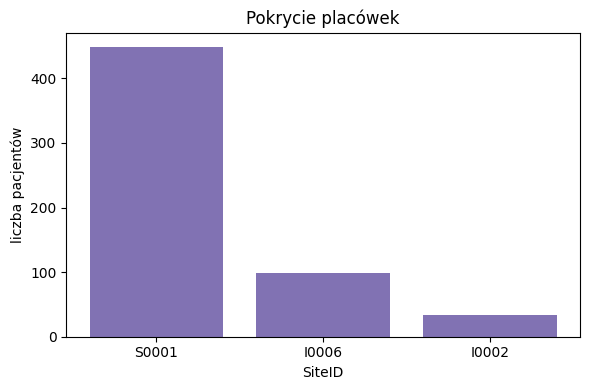

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(site_coverage.index.astype(str), site_coverage["liczba_pacjentow"], color="#8172B3")
ax.set_xlabel("SiteID")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Pokrycie placówek")
plt.tight_layout()
plt.show()

Pod kątem placówek zbiór jest silnie niezbalansowany. Zdecydowana większośść badań pochodzi z jednej placówki o sygnaturze S0001. Pozostałe placówki stanowią jedynie uzupełnienie zbioru

## 1.4 Zaburzenia kognitywistyczne 

In [7]:
target_counts = (demo["Cognitive_Impairment"].value_counts(dropna=False)
                 .rename_axis("Cognitive_Impairment")
                 .rename("liczba_pacjentow").to_frame())
target_counts["odsetek_%"] = (100 * target_counts["liczba_pacjentow"] / len(demo)).round(2)
target_counts

,liczba_pacjentow,odsetek_%
Cognitive_Impairment,,
True,290,50.0
False,290,50.0


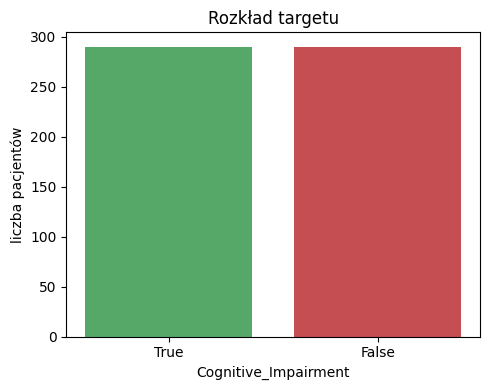

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
order = target_counts.index.astype(str)
ax.bar(order, target_counts["liczba_pacjentow"], color=["#55A868", "#C44E52"])
ax.set_xlabel("Cognitive_Impairment")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład targetu")
plt.tight_layout()
plt.show()

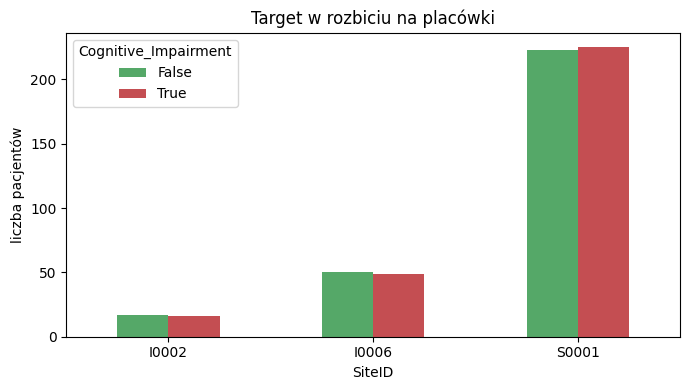

In [9]:
site_target = pd.crosstab(demo["SiteID"], demo["Cognitive_Impairment"])
ax = site_target.plot(kind="bar", figsize=(7, 4), color=["#55A868", "#C44E52"])
ax.set_xlabel("SiteID")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Target w rozbiciu na placówki")
ax.legend(title="Cognitive_Impairment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Tak jak zapewniał autor zbioru, jest on w pełni zbalansowany pod względem występowania zaburzeń poznawczych. Każda placówka posiada tyle samo pacjentów chorych i zdrowych. Jest to bardzo dobra informacja dla zbioru uczącego, bo gwarantuje, że model nie nauczy się rozpoznawać placówki a patologie. Dodatkowo zapewni zbalansowany podział na zbiór uczący, walidacyjny i testowy.

## 1.5 Wiek (Age)

In [10]:
demo["Age"].describe()

count    580.000000
mean      69.870690
std        8.557769
min       50.000000
25%       64.000000
50%       70.000000
75%       76.000000
max       89.000000
Name: Age, dtype: float64

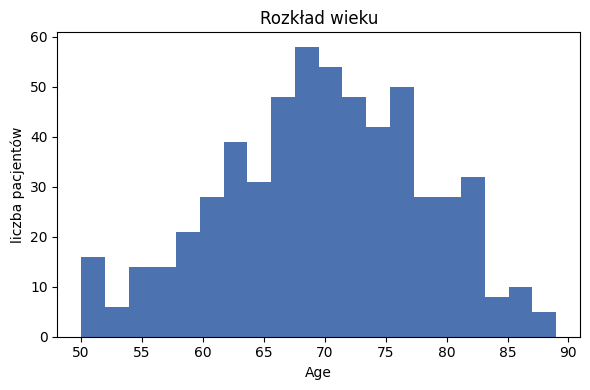

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(demo["Age"], bins=20, color="#4C72B0")
ax.set_xlabel("Age")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład wieku")
plt.tight_layout()
plt.show()

In [12]:
demo.groupby("Cognitive_Impairment")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Cognitive_Impairment,,,,,,,,
False,290.0,69.755172,8.591784,50.0,64.0,70.0,76.00,89.0
True,290.0,69.986207,8.536902,50.0,64.0,70.0,76.75,88.0


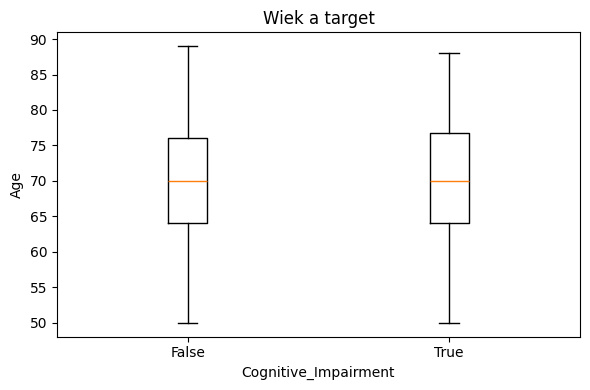

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
groups = [demo.loc[demo["Cognitive_Impairment"] == v, "Age"] for v in [False, True]]
ax.boxplot(groups, tick_labels=["False", "True"])
ax.set_xlabel("Cognitive_Impairment")
ax.set_ylabel("Age")
ax.set_title("Wiek a target")
plt.tight_layout()
plt.show()

Wiek jest kolejną świetnie zbalansowaną zmienną. Jest to kolejna świetna informacja dla danych w zbiorze. Sprawia to, że wiek nie będzie wprowadzał zbędnego szumu w danych.

## 1.6 Płeć (Sex)

In [14]:
sex_counts = (demo["Sex"].value_counts(dropna=False)
              .rename_axis("Sex").rename("liczba_pacjentow").to_frame())
sex_counts["odsetek_%"] = (100 * sex_counts["liczba_pacjentow"] / len(demo)).round(2)
sex_counts

,liczba_pacjentow,odsetek_%
Sex,,
Male,335,57.76
Female,245,42.24


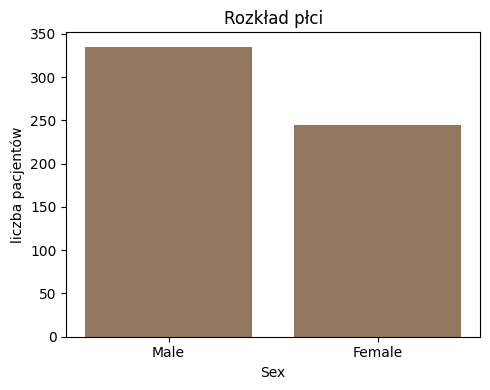

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
vc = demo["Sex"].value_counts()
ax.bar(vc.index, vc.values, color="#937860")
ax.set_xlabel("Sex")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład płci")
plt.tight_layout()
plt.show()

In [16]:
pd.crosstab(demo["Sex"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Sex,,
Female,50.61,49.39
Male,49.55,50.45


W przypadku płci zbiór już nie jest tak ściśle zbalansowany jak w przypadku poprzednich zmiennych, jednakże płcie są zbalansowane pod kątem występowania zaburzeń poznawczych. Oznacza to, że również i ta zmienna nie powinna wprowadzić szumu związanego z niezbalansowanymi klasami.

## 1.7 Rasa i pochodzenie etniczne (Race, Ethnicity)

In [17]:
(demo["Race"].value_counts(dropna=False)
 .rename_axis("Race").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
Race,
White,473
Black,64
Asian,15
Others,15
Unavailable,13


In [18]:
(demo["Ethnicity"].value_counts(dropna=False)
 .rename_axis("Ethnicity").rename("liczba_pacjentow").to_frame())

,liczba_pacjentow
Ethnicity,
Not Hispanic,531
Unavailable,32
Hispanic,17


In [19]:
pd.crosstab(demo["Race"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Race,,
Asian,46.67,53.33
Black,48.44,51.56
Others,46.67,53.33
Unavailable,23.08,76.92
White,51.16,48.84


In [20]:
pd.crosstab(demo["Ethnicity"], demo["Cognitive_Impairment"], normalize="index").mul(100).round(2)

Cognitive_Impairment,False,True
Ethnicity,,
Hispanic,41.18,58.82
Not Hispanic,49.34,50.66
Unavailable,65.62,34.38


Rasa i pochodzenie etniczne również jest zbalansowane pod względem zaburzeń, jednak nie dla pacjentów, u których dana cecha jest nieokreślona.

## 1.8 BMI

In [21]:
demo["BMI"].describe()

count    366.000000
mean      29.831421
std        6.568252
min       18.110000
25%       25.082500
50%       28.645000
75%       33.520000
max       71.540000
Name: BMI, dtype: float64

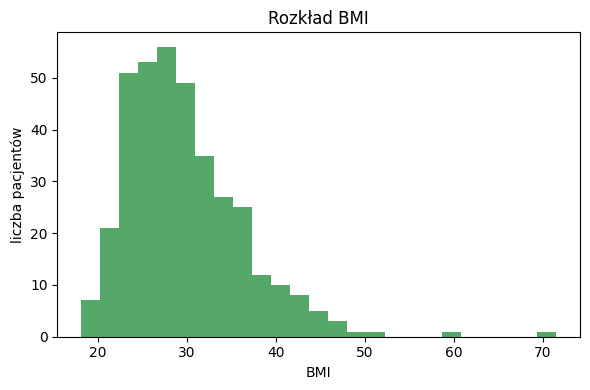

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(demo["BMI"].dropna(), bins=25, color="#55A868")
ax.set_xlabel("BMI")
ax.set_ylabel("liczba pacjentów")
ax.set_title("Rozkład BMI")
plt.tight_layout()
plt.show()

Rozkład BMI jest rozkładem prawoskośnym, występuje kilku pacjentów o bardzo wysokim BMI. Pod względem zaburzeń jest on zbalansowany jak każda inna zmienna w zbiorze. Dodatkowo w tej zmiennej występuje wiele braków, co sprawia, że nie jest to dobra cecha opisująca.

## 1.9 Podsumowanie
Wszystkie cechy znajdujące się w pliku demographics.csv są bardzo dobrze zbalansowana. Oznacza to, że zbiór jest świetnie przygotowany pod analizę wpływu samych parametrów zmierzonych podczas badania. Model lepiej będzie rozpoznawał cechy związane z samymi zaburzeniami poznawczymi a nie z wiekiem czy płcią. Jest to bardzo duże ułatwienie i pozwala podzielić zbiór tylko i wyłącznie pod względem cechy opisywanej i nie będzie wymagał sztucznego balansowania klas. Niestety niesie to też za sobą zagrożenie związane z tym, że jeśli model nauczony na takich danych będzie później używany do przewidywania, nie będzie on brał pod uwagę żadnej z tych cech, mimo że w prawdziwym życiu mogą one nieść za sobą jakąś informację. Cechy te same w sobie nie będą rozróżniać pacjentów chorych od zdrowych, ale mogą wchodzić w interakcje z cechami sygnałowymi, dlatego decyzja o włączeniu cech demograficznych do modelu zostaje odłożona do fazy modelowania. Dodatkowo BMI zawiera wiele braków i będzie musiało zostać uzupełnione w sposób sztuczny.

# 2. Podział pacjentów na zbiory uczący, walidacyjny i testowy (70/15/15)

Podział głównego zbioru jest zamrażany przed wykonaniem analizy związku cech sygnału z targetem.

Założenia podziału:
- Proporcje 70 / 15 / 15: trening / walidacja / test.
- Podział po Cognitive_Impairment i placówce ze względu na dysproporjcę w tej cesze.
- Jeden podział na trzy części naraz.

## 2.1 Definicja klucza podziału
Jest potrzbena, żeby zachować balans między poszczególnymi placówkami. Celem jest uniknięcie sytuacji, w której cały zbiór uczący jest z jednej placówki a zbiór testowy z drugiej.

In [23]:
demo["strata"] = (demo["SiteID"].astype(str) + " | "
                  + demo["Cognitive_Impairment"].astype(str))
strata_counts = demo["strata"].value_counts().sort_index()
strata_counts

strata
I0002 | False     17
I0002 | True      16
I0006 | False     50
I0006 | True      49
S0001 | False    223
S0001 | True     225
Name: count, dtype: int64

## 2.2 Wykonanie podziału

In [24]:
def stratified_three_way_split(strata_labels, ids, props=(0.70, 0.15, 0.15),
                                names=("train", "val", "test"), seed=0):
    props = np.asarray(props, dtype=float)
    rng = np.random.default_rng(seed)
    assignment = np.empty(len(ids), dtype=object)

    for stratum in np.unique(strata_labels):
        idx = np.where(strata_labels == stratum)[0]
        idx_shuffled = rng.permutation(idx)
        n = len(idx_shuffled)

        n_val = int(np.floor(n * props[1]))
        n_test = int(np.floor(n * props[2]))
        n_train = n - n_val - n_test

        assignment[idx_shuffled[:n_train]] = names[0]
        assignment[idx_shuffled[n_train:n_train + n_val]] = names[1]
        assignment[idx_shuffled[n_train + n_val:]] = names[2]

    return assignment

In [25]:
demo["patient_id"] = demo["BidsFolder"]
demo["split"] = stratified_three_way_split(
    strata_labels=demo["strata"].to_numpy(),
    ids=demo["patient_id"].to_numpy(),
    props=(0.70, 0.15, 0.15),
    names=("train", "val", "test"),
    seed=SEED,
)
demo["split"].value_counts()

split
train    412
test      84
val       84
Name: count, dtype: int64

## 2.3 Weryfikacja
W tym podrozdziale zostanie sprawdzone czy podział został wykonany równomiernie względem różnych cech.

In [26]:
site_split = pd.crosstab(demo["SiteID"], demo["split"]).reindex(
    columns=["train", "val", "test"]
)
site_split["total"] = site_split.sum(axis=1)
site_split

split,train,val,test,total
SiteID,,,,
I0002,25,4,4,33
I0006,71,14,14,99
S0001,316,66,66,448


In [27]:
(pd.crosstab(demo["SiteID"], demo["split"], normalize="index")
 .reindex(columns=["train", "val", "test"]).mul(100).round(2))

split,train,val,test
SiteID,,,
I0002,75.76,12.12,12.12
I0006,71.72,14.14,14.14
S0001,70.54,14.73,14.73


In [28]:
pd.crosstab(demo["split"], demo["Cognitive_Impairment"]).reindex(["train", "val", "test"])

Cognitive_Impairment,False,True
split,,
train,206,206
val,42,42
test,42,42


In [29]:
(pd.crosstab(demo["split"], demo["Cognitive_Impairment"], normalize="index")
 .reindex(["train", "val", "test"]).mul(100).round(2))

Cognitive_Impairment,False,True
split,,
train,50.0,50.0
val,50.0,50.0
test,50.0,50.0


In [30]:
(pd.crosstab(demo["split"], demo["Sex"], normalize="index")
 .reindex(["train", "val", "test"]).mul(100).round(2))

Sex,Female,Male
split,,
train,41.99,58.01
val,42.86,57.14
test,42.86,57.14


In [31]:
demo.groupby("split")["Age"].describe().reindex(["train", "val", "test"])

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,412.0,70.092233,8.532533,50.0,64.00,70.0,76.25,89.0
val,84.0,68.845238,9.087916,50.0,63.00,68.5,75.00,89.0
test,84.0,69.809524,8.152871,50.0,65.75,70.0,75.00,86.0


## 2.4 Zapis podziału

In [32]:
assign_cols = ["patient_id", "SiteID", "BDSPPatientID", "SessionID", "Cognitive_Impairment", "split"]
assignments = demo[assign_cols].sort_values(["split", "patient_id"]).reset_index(drop=True)
assignments.to_csv(SPLITS_DIR / "assignments.csv", index=False)

split_payload = {
    "seed": SEED,
    "proportions": {"train": 0.70, "val": 0.15, "test": 0.15},
    "granularity": "patient",
    "stratify_by": ["SiteID", "Cognitive_Impairment"],
    "n_total": int(len(demo)),
    "sizes": {k: int(v) for k, v in demo["split"].value_counts().items()},
    "splits": {
        name: sorted(demo.loc[demo["split"] == name, "patient_id"].tolist())
        for name in ("train", "val", "test")
    },
}
(SPLITS_DIR / "split.json").write_text(json.dumps(split_payload, indent=2, ensure_ascii=False))
print(f"Zapisano: assignments.csv ({len(assignments)} wierszy), split.json")

Zapisano: assignments.csv (580 wierszy), split.json


## 2.4 Podsumowanie
Podział zbioru na treningowy, walidacyjny i testowy został wykonany poprawnie. W każdym ze zbiorów cechy rozłożyły się względnie równomiernie, w proporcjach zachowanych z pełnego zbioru. W każdym zbiorze liczba pacjentów chorych i zdrowych jest taka sama. Rozkład płci jest delikatnie nierównomierny na rzecz mężczyzn, jednak jest to wynik tego, że zbiór pierwotny również zawierał taką nierównomierność. Stratyfikacja po placówce zapewniła, że każda placówka zachowała swoje proporcje (chorych/zdrowych) w każdym zbiorze  Placówka z najmniejszą ilością danych została podzielona najgorzej ze względu na małą ilość pacjentów do podziału.Od tego momentu cała dalsza analiza eksploracyjna prowadzona jest wyłącznie na zbiorze treningowym. Zbiory walidacyjny i testowy pozostają niewidziane, aby ich wyniki uczciwie szacowały jakość modelu na nowych pacjentach.